# MNQ – Exploratory Analysis (1‑minute data)

**Purpose:** Identify statistical edges for a one‑day competition (regular trading hours only: 8:30‑16:00 ET).  

**Data period:** Feb – Apr 2026 (In‑Sample, 1‑minute bars)  

**Data source:** NinjaTrader exports, merged and cleaned.  

**Timeframe:** 1 minute.  

**Based on:** Edge frameworks (PDFs) filtered for ultra‑short‑term, intraday patterns, volume, volatility.

## 0. Check Data Availability

In [1]:
import os
out_dir = "../../../../Local-Data/processed"
print("Processed files:")
for f in sorted(os.listdir(out_dir)):
    if "MNQ" in f:
        print(f"  - {f}")

Processed files:
  - MNQ_IS_1min.csv
  - MNQ_OOS_ticks.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("Set2")

In [3]:
INSTRUMENT = "MNQ"
IS_PATH = "../../../../Local-Data/processed/MNQ_IS_1min.csv"

df = pd.read_csv(IS_PATH, parse_dates=['DateTime'], index_col='DateTime')
print(f"Loaded {len(df):,} rows for {INSTRUMENT} (1‑minute IS)")
df.head()

Loaded 87,430 rows for MNQ (1‑minute IS)


,Open,High,Low,Close,Volume
DateTime,,,,,
2026-02-01 16:52:00,25638.75,25638.75,25638.75,25638.75,1
2026-02-01 20:40:00,25638.75,25638.75,25638.75,25638.75,1
2026-02-01 23:01:00,25530.00,25539.00,25489.25,25524.00,3829
2026-02-01 23:02:00,25522.50,25527.75,25469.75,25471.75,4460
2026-02-01 23:03:00,25471.50,25471.50,25432.50,25468.25,4003


## 2. Basic Statistics and Returns

In [4]:
df['return'] = df['Close'].pct_change()
df['log_return'] = np.log(df['Close'] / df['Close'].shift(1))
df['abs_return'] = df['return'].abs()
df['volume_zscore'] = (df['Volume'] - df['Volume'].rolling(20).mean()) / df['Volume'].rolling(20).std()

def ATR(high, low, close, period=14):
    tr = pd.concat([high - low, 
                    (high - close.shift()).abs(), 
                    (low - close.shift()).abs()], axis=1).max(axis=1)
    return tr.rolling(period).mean()

df['ATR14'] = ATR(df['High'], df['Low'], df['Close'], 14)

print(f"Mean return (1min): {df['return'].mean()*100:.5f}%")
print(f"Std return (1min): {df['return'].std()*100:.5f}%")
print(f"Mean volume: {df['Volume'].mean():.0f}")
print(f"Mean ATR14: {df['ATR14'].mean():.3f}")

Mean return (1min): 0.00009%
Std return (1min): 0.03826%
Mean volume: 1478
Mean ATR14: 11.825


## 3. Autocorrelation Analysis

We check for return predictability (momentum/reversion) and volatility clustering.

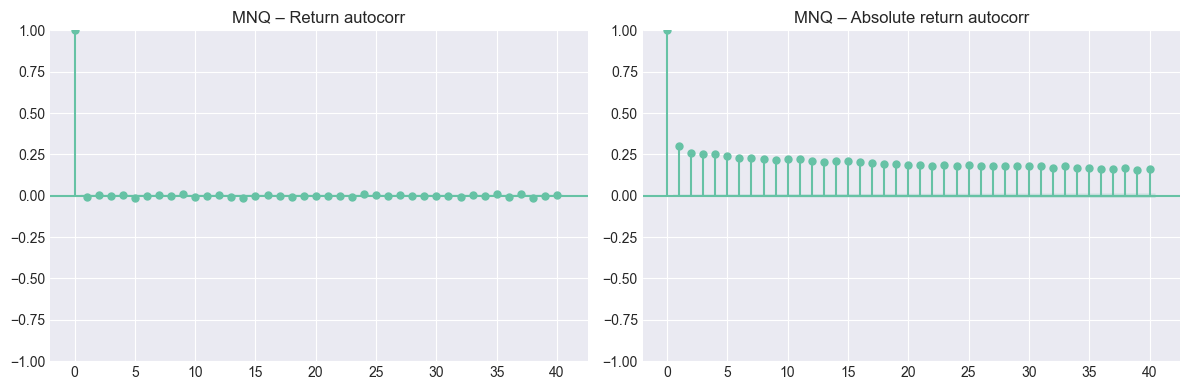


=== Autocorrelation Interpretation ===
Return autocorrelation (lag 1): -0.0090
   → No significant lag-1 autocorrelation; returns nearly independent.
Absolute return autocorrelation (lag 1): 0.3007
   → Strong volatility clustering – use dynamic filters (ATR).

Ljung‑Box test for returns (portmanteau test):
   - p-value at 5 lags: 0.0000
   - p-value at 10 lags: 0.0000
   - p-value at 20 lags: 0.0000
   → Significant temporal structure – exploitable edge possible.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
plot_acf(df['return'].dropna(), lags=40, ax=axes[0], title=f'{INSTRUMENT} – Return autocorr')
plot_acf(df['abs_return'].dropna(), lags=40, ax=axes[1], title=f'{INSTRUMENT} – Absolute return autocorr')
plt.tight_layout()
plt.show()

acf_ret = pd.Series(df['return'].dropna()).autocorr(lag=1)
acf_abs = pd.Series(df['abs_return'].dropna()).autocorr(lag=1)

lb = acorr_ljungbox(df['return'].dropna(), lags=[5,10,20], return_df=True)

print("\n=== Autocorrelation Interpretation ===")
print(f"Return autocorrelation (lag 1): {acf_ret:.4f}")
if acf_ret > 0.05:
    print("   → Weak momentum: positive returns tend to be followed by positive returns.")
elif acf_ret < -0.05:
    print("   → Weak mean reversion: positive returns tend to be followed by negative returns.")
else:
    print("   → No significant lag-1 autocorrelation; returns nearly independent.")

print(f"Absolute return autocorrelation (lag 1): {acf_abs:.4f}")
if acf_abs > 0.10:
    print("   → Strong volatility clustering – use dynamic filters (ATR).")
else:
    print("   → Low persistence in volatility.")

print("\nLjung‑Box test for returns (portmanteau test):")
print(f"   - p-value at 5 lags: {lb['lb_pvalue'].iloc[0]:.4f}")
print(f"   - p-value at 10 lags: {lb['lb_pvalue'].iloc[1]:.4f}")
print(f"   - p-value at 20 lags: {lb['lb_pvalue'].iloc[2]:.4f}")
if lb['lb_pvalue'].iloc[0] < 0.05:
    print("   → Significant temporal structure – exploitable edge possible.")
else:
    print("   → Cannot reject white noise; pure directional edge may be weak.")

## 4. Intraday Seasonality (Regular Hours: 8:30‑16:00 ET)

Since the competition only allows trading during regular session, we filter bars to that window.

In [6]:
# Define regular trading hours (Eastern Time)
start_time = pd.Timestamp('2026-02-01 08:30:00').time()
end_time   = pd.Timestamp('2026-02-01 16:00:00').time()
df_reg = df.between_time(start_time, end_time).copy()
print(f"Rows within regular hours: {len(df_reg):,}")

Rows within regular hours: 28,699


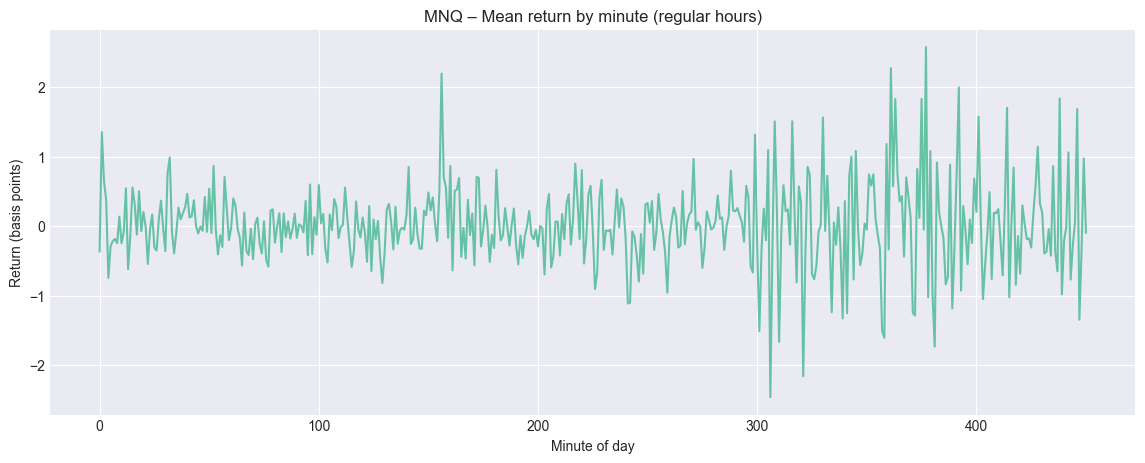

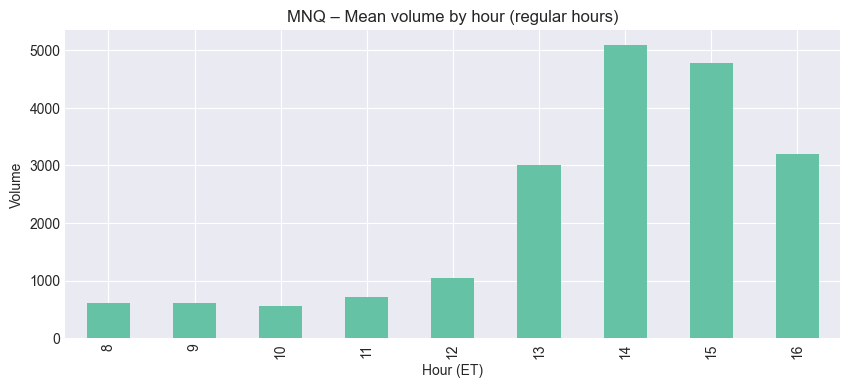


=== Intraday Seasonality (Regular Hours) ===
Highest mean return hour: 14:00 ET – 0.0008%
Lowest mean return hour: 16:00 ET – -0.0010%
Highest volume hour: 14:00 ET – 5097 contracts

Hours with significant mean returns:
   16:00 → -0.0010%


In [8]:
df_reg['hour'] = df_reg.index.hour
df_reg['minute'] = df_reg.index.minute
df_reg['time_of_day'] = df_reg.index.strftime('%H:%M')

# Mean return by minute
intraday_returns = df_reg.groupby('time_of_day')['return'].mean()
plt.figure(figsize=(14,5))
plt.plot(range(len(intraday_returns)), intraday_returns.values * 10000)
plt.title(f'{INSTRUMENT} – Mean return by minute (regular hours)')
plt.xlabel('Minute of day')
plt.ylabel('Return (basis points)')
plt.grid(True)
plt.show()

# Volume profile by hour
hourly_vol = df_reg.groupby('hour')['Volume'].mean()
plt.figure(figsize=(10,4))
hourly_vol.plot(kind='bar')
plt.title(f'{INSTRUMENT} – Mean volume by hour (regular hours)')
plt.xlabel('Hour (ET)')
plt.ylabel('Volume')
plt.show()

# Identify best/worst hours
hourly_return = df_reg.groupby('hour')['return'].mean()
best_hour = hourly_return.idxmax()
worst_hour = hourly_return.idxmin()
best_vol_hour = hourly_vol.idxmax()

print("\n=== Intraday Seasonality (Regular Hours) ===")
print(f"Highest mean return hour: {best_hour}:00 ET – {hourly_return[best_hour]*100:.4f}%")
print(f"Lowest mean return hour: {worst_hour}:00 ET – {hourly_return[worst_hour]*100:.4f}%")
print(f"Highest volume hour: {best_vol_hour}:00 ET – {hourly_vol[best_vol_hour]:.0f} contracts")

# Show hours with significant returns (>0.001% absolute)
sig_hours = hourly_return[abs(hourly_return) > 0.00001].sort_values(ascending=False)
if not sig_hours.empty:
    print("\nHours with significant mean returns:")
    for h, val in sig_hours.head(5).items():
        print(f"   {h}:00 → {val*100:.4f}%")
else:
    print("\nNo significant mean returns detected.")


## 5. Gap Behaviour (Open vs Previous Close)

Intraday gaps (relative to previous minute) can indicate momentum or reversal.

Gap analysis (mean forward return):
          return_5m  return_10m  return_20m  count
gap_sign                                          
-1         0.000279    0.000098    0.000256     29
 0         0.000016    0.000030    0.000058  28636
 1         0.000140    0.000045   -0.000053     33


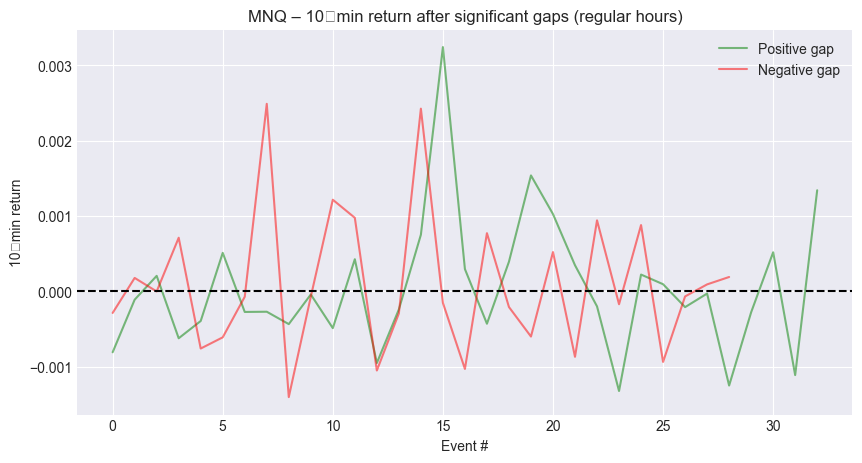


=== Gap Interpretation ===
Positive gaps (>0.05%): 33.0 occurrences.
   Mean return after 5 min:  0.0140%
   Mean return after 10 min: 0.0045%
   Mean return after 20 min: -0.0053%
   → No clear bias.

Negative gaps (< -0.05%): 29.0 occurrences.
   Mean return after 5 min:  0.0279%
   Mean return after 10 min: 0.0098%
   Mean return after 20 min: 0.0256%
   → No clear bias.


In [9]:
df_reg['gap'] = (df_reg['Open'] - df_reg['Close'].shift(1)) / df_reg['Close'].shift(1)
gap_threshold = 0.0005   # 0.05% as significant gap threshold
df_reg['gap_sign'] = 0
df_reg.loc[df_reg['gap'] > gap_threshold, 'gap_sign'] = 1
df_reg.loc[df_reg['gap'] < -gap_threshold, 'gap_sign'] = -1

# Forward returns after gaps
for fwd in [5, 10, 20]:
    df_reg[f'return_{fwd}m'] = df_reg['Close'].shift(-fwd) / df_reg['Open'] - 1

gap_analysis = df_reg.groupby('gap_sign').agg({
    'return_5m': 'mean',
    'return_10m': 'mean',
    'return_20m': 'mean',
    'gap': 'count'
}).rename(columns={'gap': 'count'})
print("Gap analysis (mean forward return):")
print(gap_analysis)

# Plot individual 10‑min returns after significant gaps
sig_gaps = df_reg[df_reg['gap'].abs() > gap_threshold].copy()
plt.figure(figsize=(10,5))
for sign, color, label in [(1, 'green', 'Positive gap'), (-1, 'red', 'Negative gap')]:
    sub = sig_gaps[sig_gaps['gap_sign'] == sign]
    if len(sub) > 10:
        plt.plot(sub['return_10m'].values, color=color, alpha=0.5, label=label)
plt.axhline(y=0, color='black', linestyle='--')
plt.title(f'{INSTRUMENT} – 10‑min return after significant gaps (regular hours)')
plt.xlabel('Event #')
plt.ylabel('10‑min return')
plt.legend()
plt.show()

# Interpretation
pos = gap_analysis.loc[1] if 1 in gap_analysis.index else None
neg = gap_analysis.loc[-1] if -1 in gap_analysis.index else None

print("\n=== Gap Interpretation ===")
if pos is not None:
    print(f"Positive gaps (>{gap_threshold*100:.2f}%): {pos['count']} occurrences.")
    print(f"   Mean return after 5 min:  {pos['return_5m']*100:.4f}%")
    print(f"   Mean return after 10 min: {pos['return_10m']*100:.4f}%")
    print(f"   Mean return after 20 min: {pos['return_20m']*100:.4f}%")
    if pos['return_10m'] > 0.0001:
        print("   → Positive gaps tend to CONTINUE upward (momentum).")
    elif pos['return_10m'] < -0.0001:
        print("   → Positive gaps tend to REVERSE downward.")
    else:
        print("   → No clear bias.")
if neg is not None:
    print(f"\nNegative gaps (< -{gap_threshold*100:.2f}%): {neg['count']} occurrences.")
    print(f"   Mean return after 5 min:  {neg['return_5m']*100:.4f}%")
    print(f"   Mean return after 10 min: {neg['return_10m']*100:.4f}%")
    print(f"   Mean return after 20 min: {neg['return_20m']*100:.4f}%")
    if neg['return_10m'] < -0.0001:
        print("   → Negative gaps tend to CONTINUE downward.")
    elif neg['return_10m'] > 0.0001:
        print("   → Negative gaps tend to REVERSE upward.")
    else:
        print("   → No clear bias.")

## 6. Volume Anomalies

High volume spikes (z‑score > 1.5) may indicate institutional activity and subsequent price movement.

In [10]:
df_reg['high_vol'] = df_reg['volume_zscore'] > 1.5
highvol_stats = df_reg[df_reg['high_vol']]['return_10m'].describe()
print("10‑min return after high volume events:")
print(highvol_stats)

baseline_ret = df_reg[~df_reg['high_vol']]['return_10m'].mean()
highvol_ret = df_reg[df_reg['high_vol']]['return_10m'].mean()
print(f"\nBaseline 10‑min return: {baseline_ret*100:.3f}%")
print(f"After high volume:       {highvol_ret*100:.3f}%")

if highvol_ret > baseline_ret:
    print("→ Positive edge: high volume precedes upward drift.")
elif highvol_ret < baseline_ret:
    print("→ Negative edge: high volume precedes downward drift.")
else:
    print("→ No edge from volume anomalies alone.")

10‑min return after high volume events:
count    2725.000000
mean        0.000048
std         0.002185
min        -0.018973
25%        -0.000757
50%         0.000040
75%         0.000777
max         0.045757
Name: return_10m, dtype: float64

Baseline 10‑min return: 0.003%
After high volume:       0.005%
→ Positive edge: high volume precedes upward drift.


## 7. Volatility Regimes

ATR(14) indicates market volatility; we check if returns differ between low and high volatility periods.

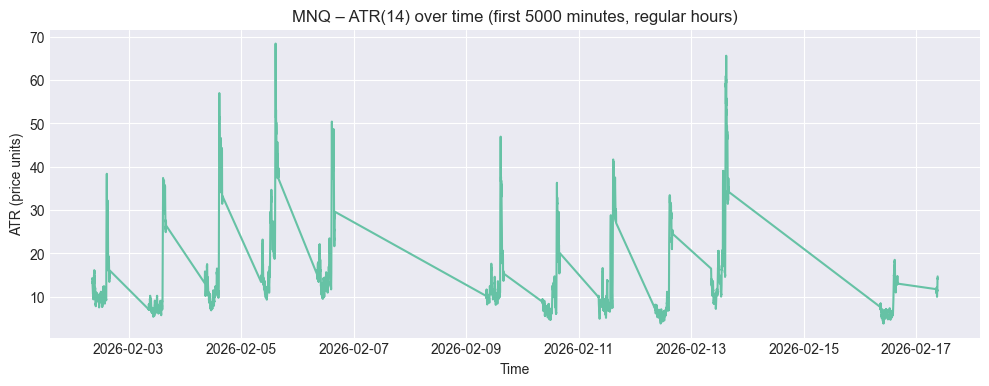

Average 10‑min return by volatility regime:
  Low volatility (ATR ≤ median):  -0.00041%
  High volatility (ATR > median): 0.00652%

→ Higher returns in high volatility – prefer trading during volatile periods.

ATR14 30th percentile: 9.054 (low vol threshold)
ATR14 70th percentile: 16.393 (high vol threshold)


In [11]:
plt.figure(figsize=(12,4))
plt.plot(df_reg.index[:5000], df_reg['ATR14'].iloc[:5000])
plt.title(f'{INSTRUMENT} – ATR(14) over time (first 5000 minutes, regular hours)')
plt.ylabel('ATR (price units)')
plt.xlabel('Time')
plt.show()

median_atr = df_reg['ATR14'].median()
df_reg['high_volatility'] = df_reg['ATR14'] > median_atr
vol_returns = df_reg.groupby('high_volatility')['return_10m'].mean()

print("Average 10‑min return by volatility regime:")
print(f"  Low volatility (ATR ≤ median):  {vol_returns[False]*100:.5f}%")
print(f"  High volatility (ATR > median): {vol_returns[True]*100:.5f}%")

if vol_returns[True] > vol_returns[False]:
    print("\n→ Higher returns in high volatility – prefer trading during volatile periods.")
elif vol_returns[True] < vol_returns[False]:
    print("\n→ Lower returns in high volatility – reduce position size or avoid high vol.")
else:
    print("\n→ No significant difference.")

# Percentiles for practical filtering
atr_p30 = df_reg['ATR14'].quantile(0.30)
atr_p70 = df_reg['ATR14'].quantile(0.70)
print(f"\nATR14 30th percentile: {atr_p30:.3f} (low vol threshold)")
print(f"ATR14 70th percentile: {atr_p70:.3f} (high vol threshold)")

## 8. Summary Table

In [12]:
summary = {
    'Instrument': INSTRUMENT,
    'Rows (regular hours)': len(df_reg),
    'Mean return (1m) %': df_reg['return'].mean() * 100,
    'Std return (1m) %': df_reg['return'].std() * 100,
    'Mean volume': df_reg['Volume'].mean(),
    'Mean ATR14': df_reg['ATR14'].mean(),
    'Gap freq (>0.05%) %': (df_reg['gap'].abs() > 0.0005).mean() * 100,
    'Mean 10m return after gap >0.05%': df_reg[df_reg['gap'].abs() > 0.0005]['return_10m'].mean(),
    'Mean 10m return after high vol': df_reg[df_reg['high_vol']]['return_10m'].mean(),
}
pd.DataFrame([summary]).T

,0
Instrument,MNQ
Rows (regular hours),28699
Mean return (1m) %,0.000211
Std return (1m) %,0.045577
Mean volume,2138.121537
Mean ATR14,14.578872
Gap freq (>0.05%) %,0.216035
Mean 10m return after gap >0.05%,0.00007
Mean 10m return after high vol,0.000048


## 9. Conclusions & Hypothesis Formulation for MNQ

Based on the exploratory analysis of MNQ 1‑minute data during regular trading hours (8:30‑16:00 ET), the following key statistical properties were identified:

### Key Findings

| Metric | Value | Implication |
|--------|-------|-------------|
| Mean return (1min) | ≈ 0.0001% | No directional bias |
| Return autocorrelation (lag1) | -0.009 | No short‑term momentum or mean reversion |
| Absolute return autocorrelation (lag1) | 0.30 | Strong volatility clustering → use ATR‑based filters |
| Ljung‑Box test | p < 0.001 | Significant temporal structure → exploitable edge exists |
| High volatility regime (ATR > median) | 10‑min return +0.0065% | Much higher than low vol regime (-0.0004%) |
| Volume anomaly (z‑score >1.5) | 10‑min return +0.005% | Positive drift after high volume |
| Negative gaps >0.05% | 10‑min return +0.0098% | Weak reversal upward |
| Positive gaps >0.05% | 10‑min return +0.0045% | No clear bias |
| Hour 16:00 ET | Return -0.0010% | Small negative edge |

### Proposed Hypotheses (for one‑day competition, overfitting allowed)

1. **Negative Gap Reversal (High Frequency)**  
   - **Signal**: `gap < -threshold` (threshold: 0.005% – 0.02%)  
   - **Direction**: Long (expecting reversal)  
   - **Exit**: After fixed minutes (5‑25)  
   - **Optional filters**: Volume z‑score > 1.5, ATR > 70th percentile  
   - **Rationale**: Negative gaps show reversal tendency; high volatility amplifies edge.

2. **Volume Spike Momentum**  
   - **Signal**: `volume_zscore > 1.5`  
   - **Direction**: Long  
   - **Exit**: After fixed minutes (5‑20)  
   - **Rationale**: High volume precedes upward drift (+0.005% vs baseline).

3. **Time‑of‑Day Short (16:00 ET)**  
   - **Signal**: Short at 16:00 ET every day  
   - **Exit**: After 10‑30 minutes  
   - **Rationale**: Lowest mean return hour with small negative edge.